# A3 — Images: A Quantum Digit Reader

Vivekananda GN

Classify handwritten digits (8×8 pixel images, built into scikit-learn) using a 4-qubit quantum kernel. We see the images, the predictions, and the mistakes.

In [ ]:
# Run once (Google Colab or local). Qibo = open-source quantum simulator (qibo.science)
!pip install -q qibo scikit-learn matplotlib scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 369.5/369.5 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 347.2/347.2 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 6.3 MB/s eta 0:00:00


In [ ]:
import numpy as np, matplotlib.pyplot as plt
from qibo import Circuit, gates, set_backend
set_backend("numpy")
np.set_printoptions(precision=3, suppress=True)
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

[Qibo 0.3.5|INFO|2026-10-03 04:17:28]: Using numpy backend on /CPU:0
INFO:qibo.config:Using numpy backend on /CPU:0


In [ ]:
def feature_state(x, n=4, scale=1.0, reps=2):
    c = Circuit(n)
    for _ in range(reps):
        for q in range(n):
            c.add(gates.H(q)); c.add(gates.RY(q, scale * x[q]))
        for q in range(n - 1): c.add(gates.CNOT(q, q + 1))
        for q in range(n): c.add(gates.RZ(q, scale * x[q]))
        for q in range(n - 1): c.add(gates.CNOT(q, q + 1))
    return np.array(c().state())

def quantum_kernel(A, B, **kw):
    SA = np.array([feature_state(a, **kw) for a in A]); SB = np.array([feature_state(b, **kw) for b in B])
    return np.abs(SA.conj() @ SB.T) ** 2          # similarity of two quantum states (1 = identical)

## 1. Pick two digits (try an easy pair first: 0 vs 1, then a hard pair: 3 vs 8)

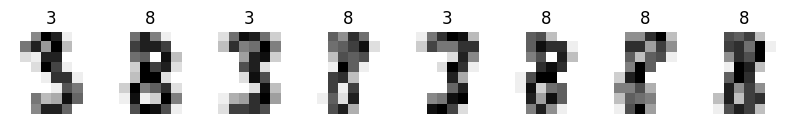

In [ ]:
DIGIT_A, DIGIT_B = 3, 8
D = load_digits(); m = np.isin(D.target, [DIGIT_A, DIGIT_B])
imgs, X, y = D.images[m], D.data[m], (D.target[m] == DIGIT_B).astype(int)
fig, ax = plt.subplots(1, 8, figsize=(10, 1.6))
for a, im, t in zip(ax, imgs[:8], D.target[m][:8]): a.imshow(im, cmap='gray_r'); a.set_title(str(t)); a.axis('off')
plt.show()

## 2. Squeeze 64 pixels into 4 numbers (PCA) → 4 qubits → quantum kernel → SVM

In [ ]:
Xa, Xb, ya, yb, Ia, Ib = train_test_split(X, y, imgs, test_size=0.3, random_state=0, stratify=y)
Xa, Xb, ya, yb = Xa[:80], Xb[:60], ya[:80], yb[:60]; Ib = Ib[:60]
pca = PCA(4).fit(Xa); sc = MinMaxScaler((0, np.pi)).fit(pca.transform(Xa))
prep = lambda A: np.clip(sc.transform(pca.transform(A)), 0, np.pi)
A, B = prep(Xa), prep(Xb)
clf = SVC(kernel='precomputed').fit(quantum_kernel(A, A, scale=0.5), ya)
pred = clf.predict(quantum_kernel(B, A, scale=0.5))
print(f"Quantum digit reader accuracy ({DIGIT_A} vs {DIGIT_B}): {np.mean(pred == yb):.2f}")
print(f"Classical RBF SVM accuracy                    : {SVC().fit(A, ya).score(B, yb):.2f}")

Quantum digit reader accuracy (3 vs 8): 0.97
Classical RBF SVM accuracy                    : 0.97


## 3. See what it sees (red titles = mistakes)

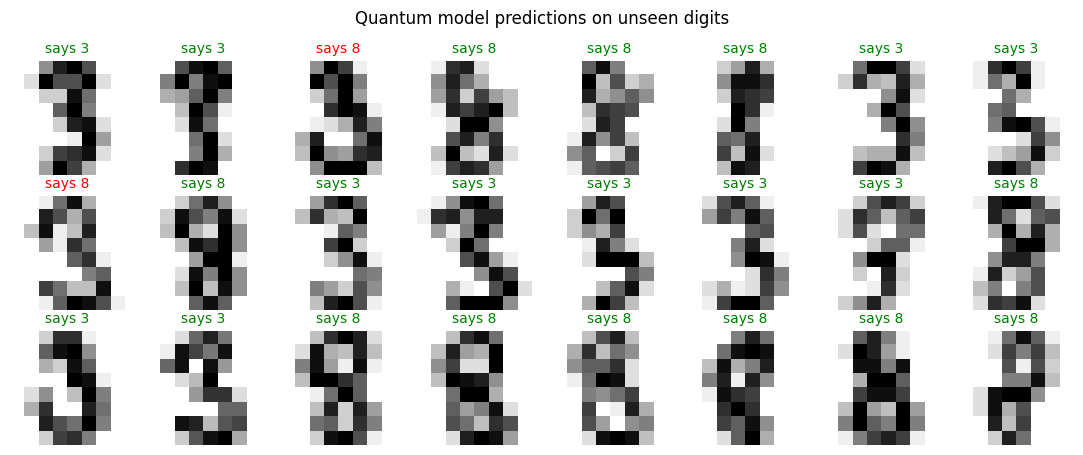

In [ ]:
fig, ax = plt.subplots(3, 8, figsize=(11, 4.6))
for a, im, p, t in zip(ax.ravel(), Ib, pred, yb):
    a.imshow(im, cmap='gray_r'); a.axis('off')
    a.set_title(f"says {[DIGIT_A, DIGIT_B][p]}", color='green' if p == t else 'red', fontsize=10)
plt.suptitle('Quantum model predictions on unseen digits'); plt.tight_layout(); plt.show()

## 4. How does it compare on different digit pairs?

In [ ]:
def run_pair(a, b):
    mm = np.isin(D.target, [a, b]); XX, yy = D.data[mm], (D.target[mm] == b).astype(int)
    xa, xb, ya_, yb_ = train_test_split(XX, yy, test_size=0.3, random_state=0, stratify=yy); xa, xb, ya_, yb_ = xa[:80], xb[:60], ya_[:80], yb_[:60]
    p = PCA(4).fit(xa); s = MinMaxScaler((0, np.pi)).fit(p.transform(xa)); f = lambda Z: np.clip(s.transform(p.transform(Z)), 0, np.pi)
    q = SVC(kernel='precomputed').fit(quantum_kernel(f(xa), f(xa), scale=0.5), ya_).score(quantum_kernel(f(xb), f(xa), scale=0.5), yb_)
    c = SVC().fit(f(xa), ya_).score(f(xb), yb_)
    return q, c
for a, b in [(0, 1), (1, 7), (3, 8), (4, 9)]:
    q, c = run_pair(a, b); print(f"digits {a} vs {b}:  quantum {q:.2f} | classical RBF {c:.2f}")

digits 0 vs 1:  quantum 1.00 | classical RBF 1.00
digits 1 vs 7:  quantum 1.00 | classical RBF 1.00
digits 3 vs 8:  quantum 0.97 | classical RBF 0.97
digits 4 vs 9:  quantum 1.00 | classical RBF 0.98


## 5. Discussion
* Real hardware today cannot load a full image into qubits cheaply. We compressed the image first (PCA); that compression does much of the work.

* where does the quantum part earn its place?
here, it is a **comparable** alternative, not a better one.

* **Try:** change `DIGIT_A, DIGIT_B`; change `scale`; use 2 qubits (2 PCA components) and see accuracy drop.